# Mall Customer Segmentation using K-Means

**Goal:** Group 200 mall customers into segments based on their income and spending, so a business can target each group differently

## Step 1: Import the tools

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Step 2: Load and check the data

In [15]:
df = pd.read_csv("Mall_Customers.csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [16]:
print(df.shape)

(200, 5)


The dataset has 200 customers and 5 columns

In [17]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


Every column has 200 values, so nothing is missing

In [18]:
print(df.describe())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


## Step 3: Clean the data
Shorten the column names and check for missing values and duplicate rows

In [19]:
df = df.rename(columns={
    "Genre":"Gender",
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Gender"].value_counts())

CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


There are no missing values and no duplicates, so the data needs no further cleaning. There are 112 females and 88 male.

## Step 4: Choose the columns and scale them
I group customers using only Income and Spending. Scaling puts both columns on the same range, so neither counts for more just because its numbers are bigger.

In [20]:
X = df[["Income","Spending"]]    #we will take only these two values

scaler = StandardScaler()        #We create the make fair tool
X_scaled = scaler.fit_transform(X)    #By this we apply it to the 2 columns
X_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

## Step 5: Choose the number of groups
K-Means needs me to pick how many groups to make. I try 1 to 10 groups and look for the point where the line stops dropping steeply (the "elbow").

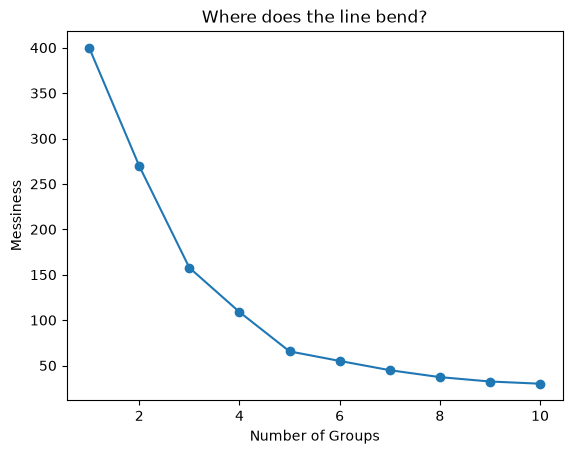

In [21]:
inertias = []    #an empty list to store scores

for k in range(1,11):  #try 1 group, 2 group,....upto 10
    model = KMeans(n_clusters=k, n_init=10, random_state = 42)  #make k-means with k groups
    model.fit(X_scaled)  #let it find the group
    inertias.append(model.inertia_)   #save how messy the groups were

plt.plot(range(1,11), inertias, marker = "o")  #draw the scores as a line
plt.xlabel("Number of Groups")
plt.ylabel("Messiness")
plt.title("Where does the line bend?")
plt.show()

The line bends at 5, so I will use 5 groups.

## Step 6: Build the customer groups
Run K-Means with 5 groups and give each customer a group number.

In [22]:
model = KMeans(n_clusters = 5, n_init = 10, random_state = 42)  #make 5 groups
df["Group"] = model.fit_predict(X_scaled)  #it gives each customer a group number

df["Group"].value_counts()


Group
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64

## Step 7: Visualise and name the groups
Plot every customer by income and spending, colored by group, then give each group a readable name based on its behavior.

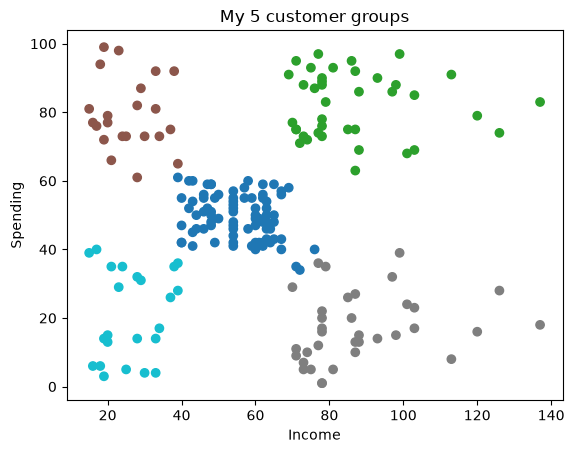

Segment
Average shoppers        81
Premium targets         39
Careful high earners    35
Budget savers           23
Impulsive spenders      22
Name: count, dtype: int64

In [23]:
plt.scatter(df["Income"], df["Spending"], c=df["Group"], cmap="tab10")
plt.xlabel("Income")
plt.ylabel("Spending")
plt.title("My 5 customer groups")
plt.show()

names = {
    0: "Average shoppers",
    1: "Premium targets",
    2: "Impulsive spenders",
    3: "Careful high earners",
    4: "Budget savers"
}

df["Segment"] = df["Group"].map(names)   # look up each customer's group number and write its name
df["Segment"].value_counts()             # count customers per segment

The 5 groups form clear, separate clumps on the chart.

## Step 8: Check the quality of the groups
The silhouette score measures how well each customer fits its own group. It runs from -1 to 1, and higher is better.

In [24]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["Group"])   # how well customers fit their own group
print("Silhouette score:", round(score, 3))

Silhouette score: 0.555


A score of 0.555 shows the groups are reasonably well separated, which supports the choice of 5 groups.

## Step 9: Describe each group
Calculate the average age, income, and spending of each group to understand who they are.

In [25]:
df.groupby("Group")[["Age", "Income", "Spending"]].mean().round(1)

,Age,Income,Spending
Group,,,
0,42.7,55.3,49.5
1,32.7,86.5,82.1
2,25.3,25.7,79.4
3,41.1,88.2,17.1
4,45.2,26.3,20.9


Group 3 has high income (88.2) but low spending (17.1), so I named it "Careful high earners". Group 2 has low income (25.7) but high spending (79.4), so I named it "Impulsive spenders".

## Step 10: Summary of all segments
A final table with each segment's size and share of all customers.

In [26]:
summary = df.groupby("Segment").agg(
    Customers=("CustomerID", "count"),     # how many customers
    Avg_Age=("Age", "mean"),               # average age
    Avg_Income=("Income", "mean"),         # average income
    Avg_Spending=("Spending", "mean")      # average spending
).round(1)

summary["Share_%"] = (summary["Customers"] / len(df) * 100).round(1)   # percent of all customers
summary.sort_values("Customers", ascending=False)

,Customers,Avg_Age,Avg_Income,Avg_Spending,Share_%
Segment,,,,,
Average shoppers,81,42.7,55.3,49.5,40.5
Premium targets,39,32.7,86.5,82.1,19.5
Careful high earners,35,41.1,88.2,17.1,17.5
Budget savers,23,45.2,26.3,20.9,11.5
Impulsive spenders,22,25.3,25.7,79.4,11.0


## Conclusion

Using K-Means clustering on income and spending score, I divided 200 mall customers into 5 distinct segments: Average shoppers (40.5%), Premium targets (19.5%), Careful high earners (17.5%), Budget savers (11.5%), and Impulsive spenders (11%). The elbow method pointed to 5 groups, and a silhouette score of 0.555 confirmed they are reasonably well separated. The results show that income alone does not decide how much a customer spends. Premium targets are the most valuable group, while Careful high earners are the biggest opportunity, since they have high incomes but spend very little. Younger customers also tended to spend more, even though age was not used to form the groups. Because the data covers only 200 customers and the spending score is a rating rather than actual sales, these findings should be treated as useful indications, not firm conclusions.